In [17]:
# Import Required Libraries

import pandas as pd
import numpy as np

In [18]:
# Load the Dataset

df = pd.read_csv("Automobile_data.csv")

In [19]:
# Display First Five Records

df.head()

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450


In [20]:
# Explore Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  205 non-null    object 
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   body-style         205 non-null    object 
 5   drive-wheels       205 non-null    object 
 6   engine-location    205 non-null    object 
 7   width              205 non-null    float64
 8   height             205 non-null    float64
 9   engine-type        205 non-null    object 
 10  engine-size        205 non-null    int64  
 11  horsepower         205 non-null    object 
 12  city-mpg           205 non-null    int64  
 13  highway-mpg        205 non-null    int64  
 14  price              205 non-null    int64  
dtypes: float64(2), int64(5), object(8)
memory usage: 24.2+ KB


In [21]:
# Generate Statistical Summary

df.describe()

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,0.834146,65.907805,53.724878,126.907317,25.219512,30.751220,13227.478049
std,1.245307,2.145204,2.443522,41.642693,6.542142,6.886443,7902.651615
min,-2.000000,60.300000,47.800000,61.000000,13.000000,16.000000,5118.000000
25%,0.000000,64.100000,52.000000,97.000000,19.000000,25.000000,7788.000000
50%,1.000000,65.500000,54.100000,120.000000,24.000000,30.000000,10345.000000
75%,2.000000,66.900000,55.500000,141.000000,30.000000,34.000000,16500.000000
max,3.000000,72.300000,59.800000,326.000000,49.000000,54.000000,45400.000000


<Axes: >

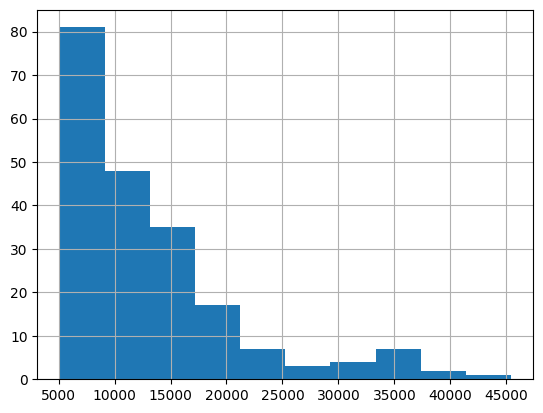

In [22]:
# Task 3: Analyze Feature Distributions
# Analyze the price column

df['price'].hist()


<Axes: >

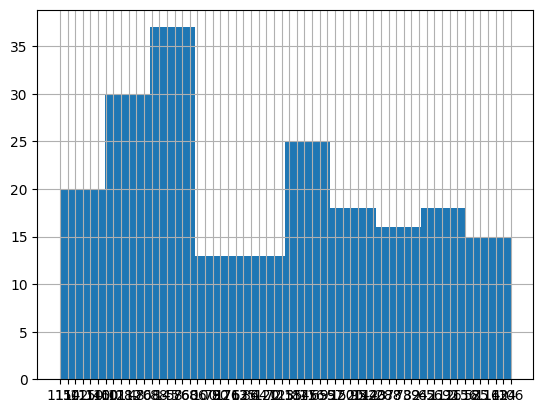

In [23]:
# Analyze the horsepower column

df['horsepower'].hist()

<Axes: >

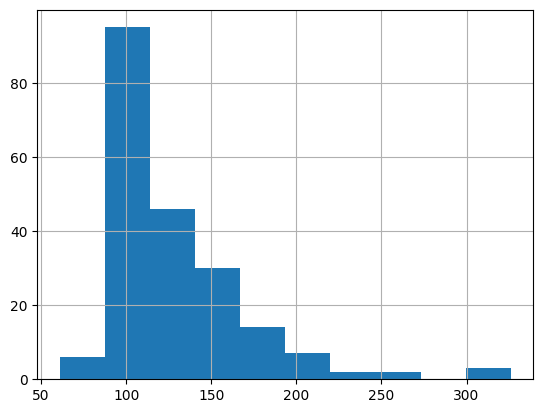

In [24]:
# Analyze the engine-size column

df['engine-size'].hist()

<Axes: >

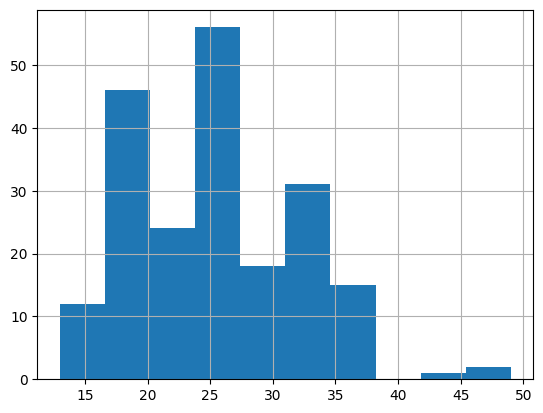

In [25]:
# Analyze the city-mpg column

df['city-mpg'].hist()

In [26]:
# Task 4: Improve Data Quality
# Standardize the dataset

df.replace("?", np.nan, inplace=True)

In [27]:
# Convert Columns to Numeric

df["normalized-losses"] = pd.to_numeric(
    df["normalized-losses"],
    errors="coerce"
)

df["horsepower"] = pd.to_numeric(
    df["horsepower"],
    errors="coerce"
)

In [28]:
# Handle Missing Values

df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


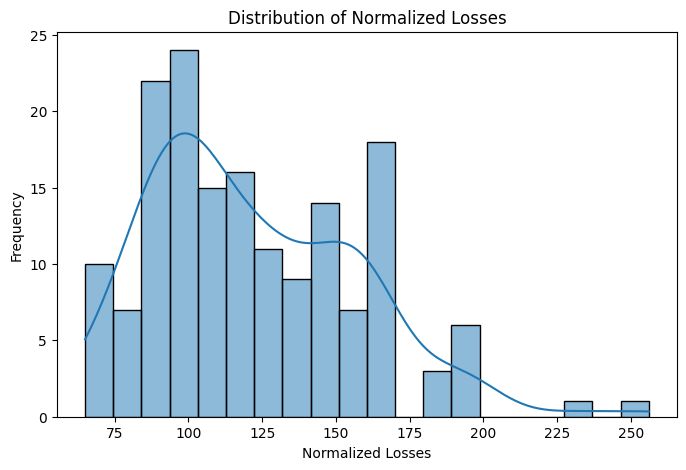

Skewness of Normalized Losses: 0.766


In [29]:
# Plot histogram to understand the skewness of these columns

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

sns.histplot(
    data = df,
    x = 'normalized-losses',
    bins=20,
    kde = True
)

plt.title('Distribution of Normalized Losses')
plt.xlabel('Normalized Losses')
plt.ylabel('Frequency')

plt.show()

# Skewness Value
print("Skewness of Normalized Losses:",
      round(df['normalized-losses'].skew(),3))

In [30]:
# Fill the missing value with Central tendency

df['horsepower'].fillna(
    df['horsepower'].median(),
    inplace = True)

/tmp/ipykernel_1166/1189920215.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['horsepower'].fillna(


In [31]:
# Check that no values are missing

df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
body-style,0
drive-wheels,0
engine-location,0
width,0
height,0
engine-type,0


In [32]:
# Check Duplicate Records

df.duplicated().sum()

np.int64(0)

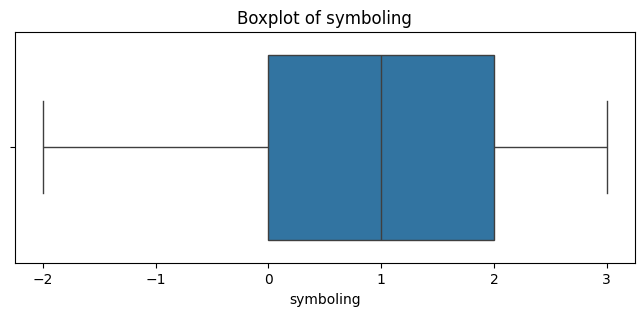

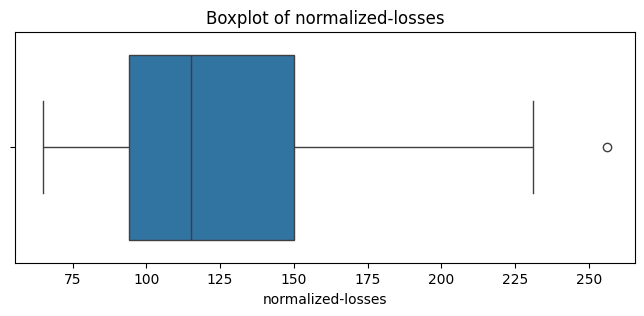

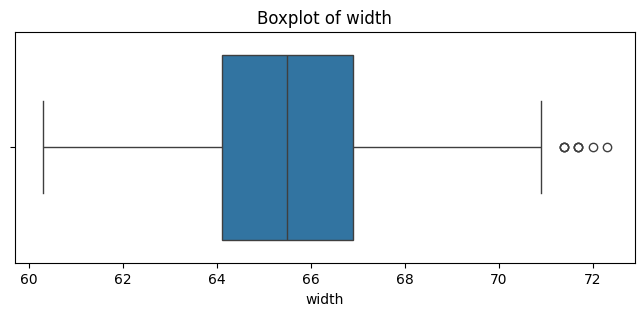

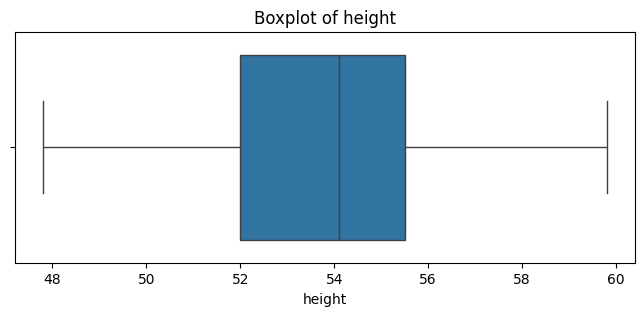

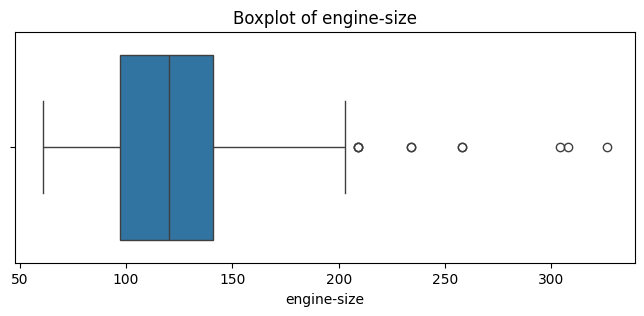

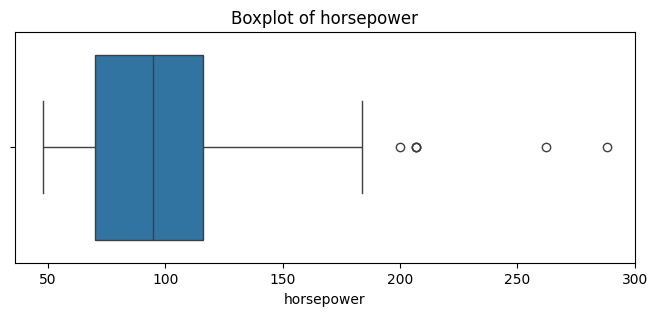

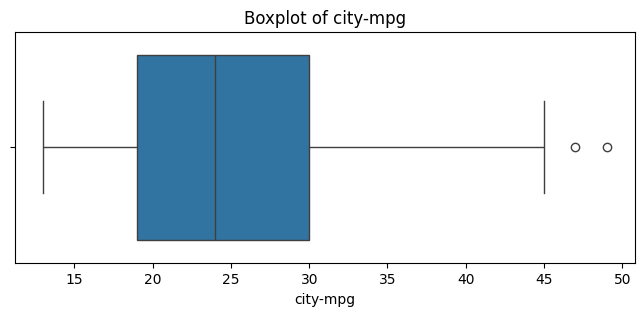

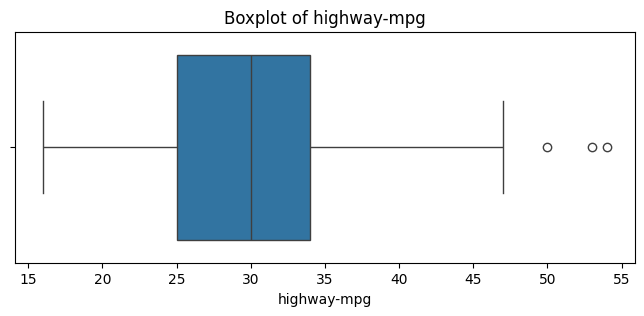

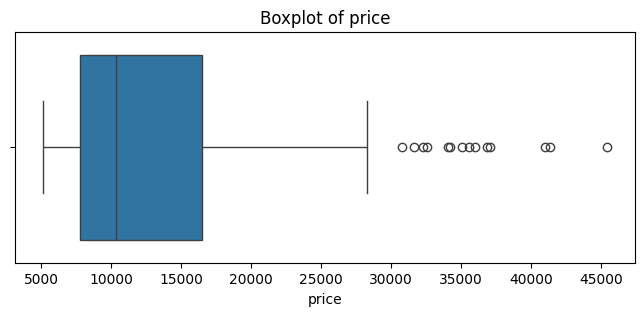

In [33]:
# Handle the Outliers
# a) First, we need to create Boxplots for the numeric Columns

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')

    plt.show()

In [52]:
# b) Observe the Boxplots and handle the outliers using IQR or
#    z score based on whether it is normally distributed or not

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    df = df[
        (df[col] >= lower_bound) &
        (df[col] <= upper_bound)]

print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (92, 15)


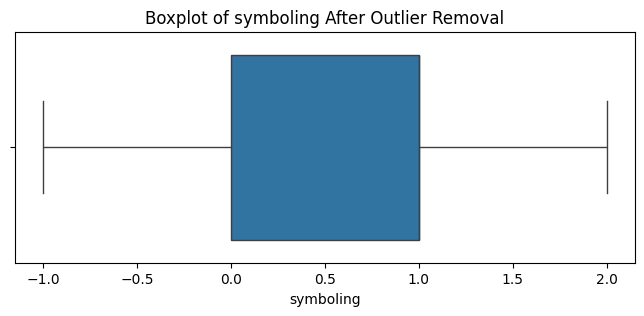

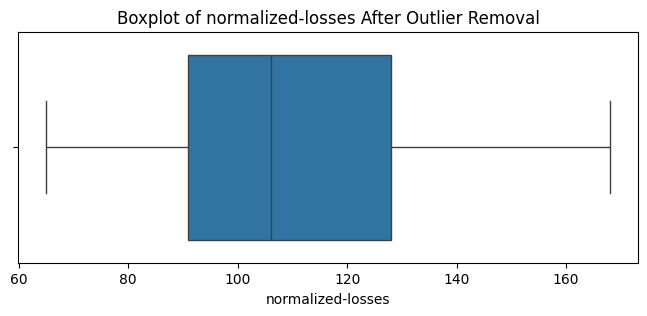

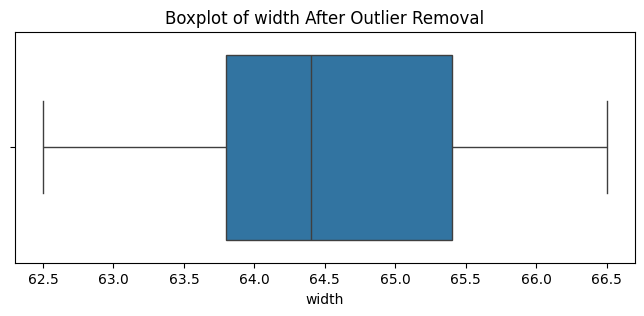

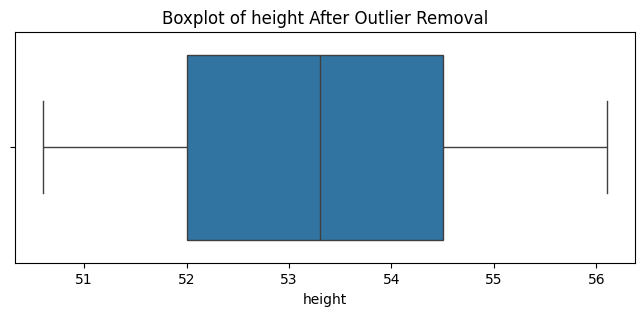

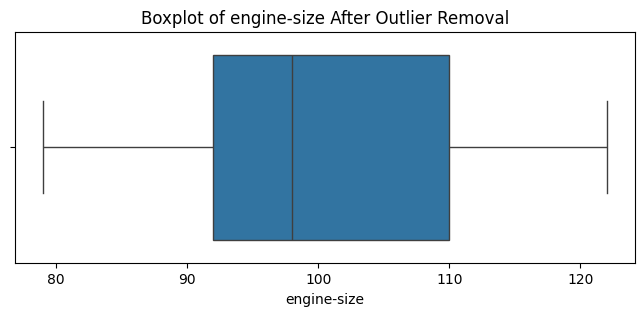

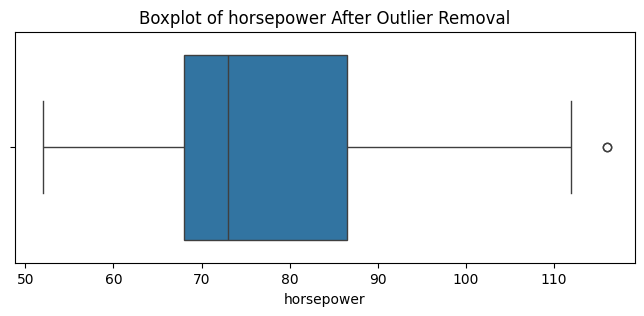

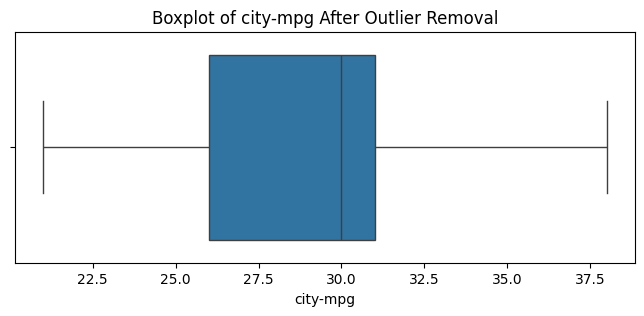

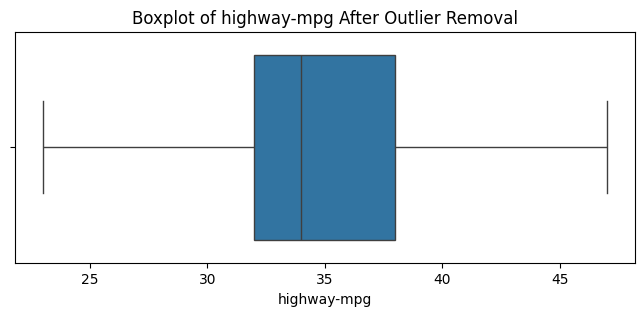

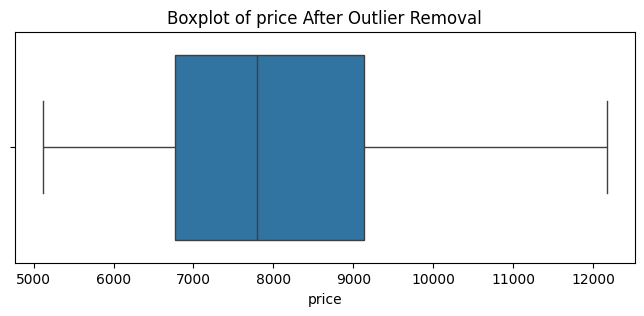

In [53]:
# c) Verify that there are no outliers left

for col in num_cols:

    plt.figure(figsize=(8,3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col} After Outlier Removal')

    plt.show()

In [36]:
# Task 4: Encode Categorical Data

# Identify the Categorical Columns and Numerical Columns

df_num=df.select_dtypes(["int64","float64"])
df_cat=df.select_dtypes(object)

In [37]:
# Select type of encoding for Categorical Columns

df_cat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 127 entries, 3 to 200
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   make             127 non-null    object
 1   fuel-type        127 non-null    object
 2   body-style       127 non-null    object
 3   drive-wheels     127 non-null    object
 4   engine-location  127 non-null    object
 5   engine-type      127 non-null    object
dtypes: object(6)
memory usage: 6.9+ KB


In [38]:
from sklearn.preprocessing import LabelEncoder
for col in df_cat :
    le=LabelEncoder() #create the object of LabelEncoder class
    df_cat[col]=le.fit_transform(df_cat[col])

In [39]:
# Lab 3: Feature Engineering   (contd......)

In [40]:
# Generate Correlation Matrix

df.corr(numeric_only=True)

,symboling,normalized-losses,width,height,engine-size,horsepower,city-mpg,highway-mpg,price
symboling,1.000000,0.483457,-0.201914,-0.445636,-0.260931,0.062235,-0.089114,0.002235,-0.110837
normalized-losses,0.483457,1.000000,0.062257,-0.406003,-0.037066,0.235052,-0.254319,-0.191595,0.216313
width,-0.201914,0.062257,1.000000,0.305671,0.691014,0.575998,-0.543340,-0.532092,0.758245
height,-0.445636,-0.406003,0.305671,1.000000,0.323635,-0.063214,-0.061575,-0.099715,0.277159
engine-size,-0.260931,-0.037066,0.691014,0.323635,1.000000,0.592220,-0.396903,-0.392745,0.550948
horsepower,0.062235,0.235052,0.575998,-0.063214,0.592220,1.000000,-0.808931,-0.792972,0.711622
city-mpg,-0.089114,-0.254319,-0.543340,-0.061575,-0.396903,-0.808931,1.000000,0.959454,-0.694821
highway-mpg,0.002235,-0.191595,-0.532092,-0.099715,-0.392745,-0.792972,0.959454,1.000000,-0.681679
price,-0.110837,0.216313,0.758245,0.277159,0.550948,0.711622,-0.694821,-0.681679,1.000000


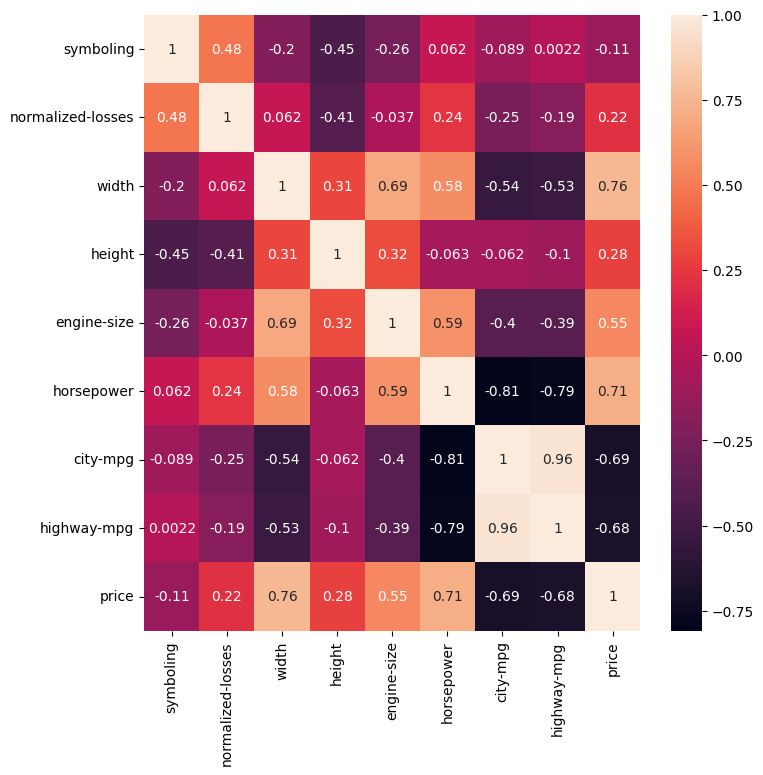

In [41]:
# Visualize Correlation Using Heatmap

plt.figure(figsize = (8,8))
sns.heatmap(df_num.corr(), annot=True)
plt.show()

In [42]:
# Task 2: Visualize Business Insights
# Integrated the new data variables

df_new = pd.concat([df_num, df_cat], axis=1)

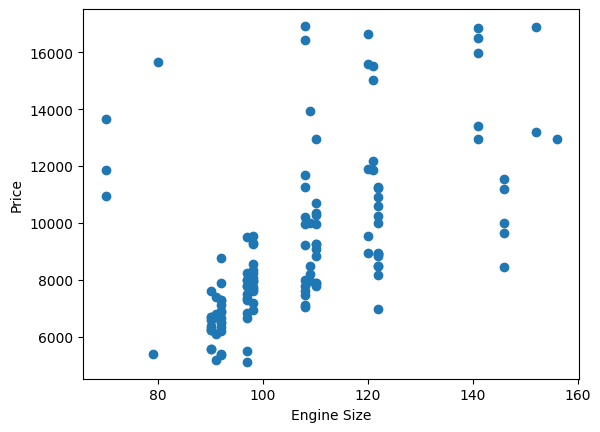

In [43]:
# Generate the Visualization for Engine Size vs Price

plt.scatter(df_new['engine-size'], df_new['price'])
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.show()

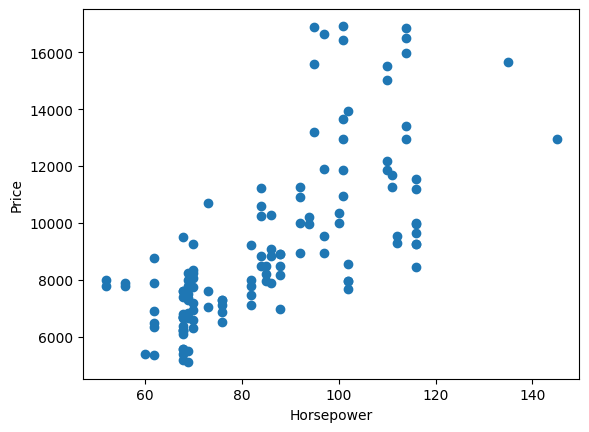

In [44]:
# Generate the Visualization for Horsepower vs Price

plt.scatter(df_new['horsepower'], df_new['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()

<Axes: xlabel='fuel-type', ylabel='price'>

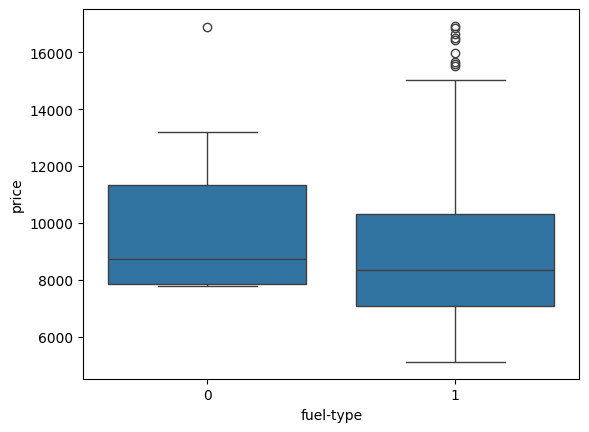

In [45]:
# Generate the Visualization for Fuel Type vs Price

sns.boxplot(x='fuel-type', y='price', data=df_new)

In [46]:
# Task 3: Scale Features for Model Training
# Apply Min-Max Scaling

from sklearn.preprocessing import MinMaxScaler

for col in df_new.columns:
    mx = MinMaxScaler()
    df_new[col] = mx.fit_transform(df_new[[col]])

In [ ]:
# Apply Standard Scaler

from sklearn.preprocessing import StandardScaler
for col in df_new:
    #create object of StandardScaler
    ss=StandardScaler()
    #call function
    df_new[col]=ss.fit_transform(df_new[[col]]) #[[]] : 2D Array

In [ ]:
# Task 4: Create New Features
# Create New Features

df_new["area"] =  df_new["width"] * df_new["height"]


In [ ]:
df_new.head()

In [49]:
num_cols = df.select_dtypes(include=np.number).columns
num_cols

Index(['symboling', 'normalized-losses', 'width', 'height', 'engine-size',
       'horsepower', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

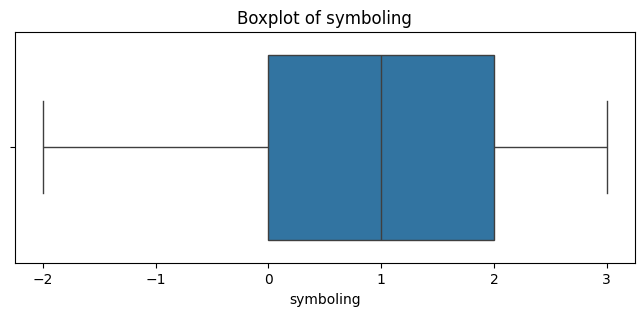

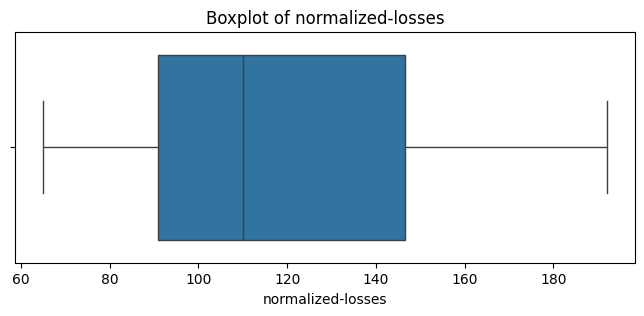

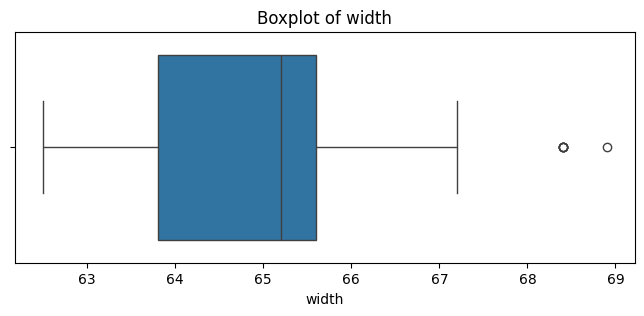

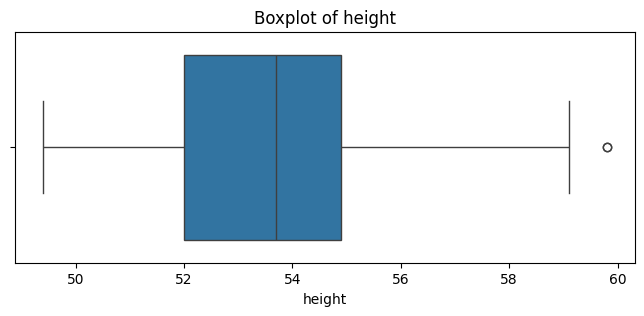

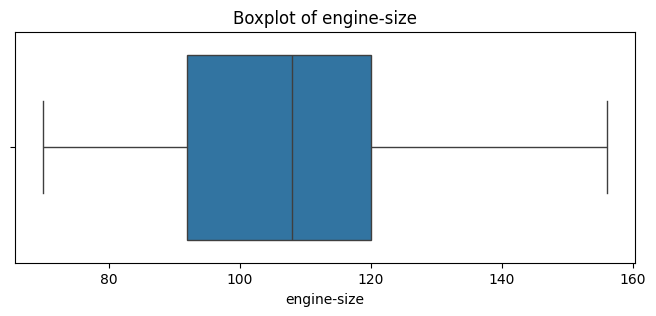

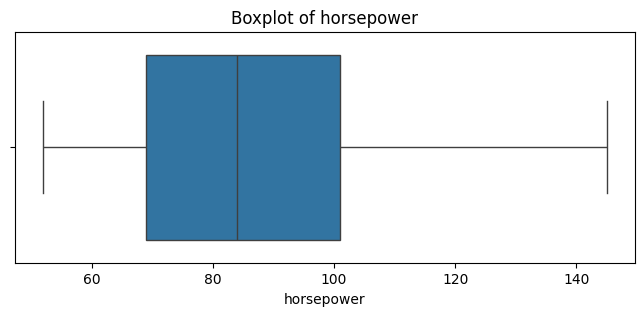

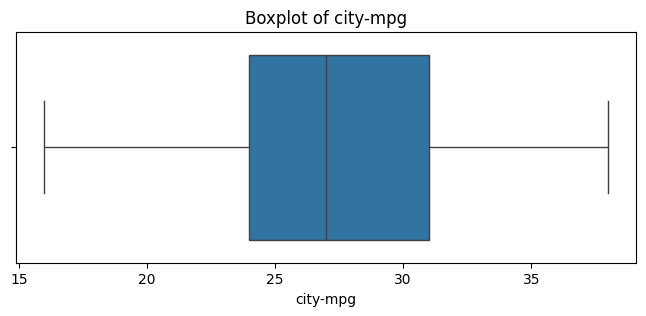

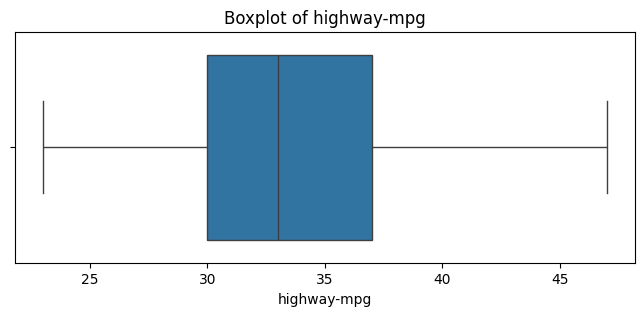

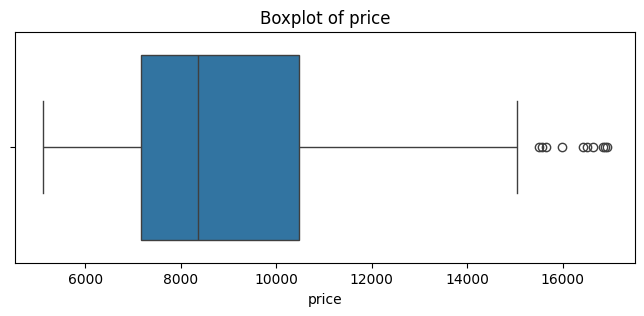

In [50]:
for col in num_cols:

    plt.figure(figsize=(8, 3))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col}')

    plt.show()